# Feature Engineering — Performances en Powerlifting

**Résultats baseline (RMSE, 5-fold CV) :**
| Modèle | RMSE |
|--------|------|
| Ridge | 105.39 |
| DecisionTree | 88.48 |
| RandomForest | 85.16 |
| **GradientBoosting** | **82.60** |

**Feature Importance (GB) :** Sex (56%) > BodyweightKg (25%) > Age (10%) > Equipment (4.5%)

**Objectif :** Créer des features utiles et mesurer leur impact.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import GradientBoostingRegressor

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')

TARGET = 'TotalKg'
y = train[TARGET].copy()
print('Train:', train.shape, '| Test:', test.shape)

Train: (105000, 18) | Test: (45000, 17)


## 1. Feature Engineering

In [2]:
def build_features(df):
    """Construire les features sur train ou test."""
    out = df.copy()

    # --- F1: WeightClassKg numérique ---
    # Extraire la partie numérique (ex: '84+' -> 84, 'Unknown' -> NaN)
    out['WeightClass_num'] = pd.to_numeric(
        out['WeightClassKg'].str.replace('+', '', regex=False),
        errors='coerce'
    )
    out['WeightClass_num'] = out['WeightClass_num'].fillna(out['BodyweightKg'])

    # --- F2: Sex × Equipment (interaction la plus importante) ---
    out['Sex_Equipment'] = out['Sex'] + '_' + out['Equipment']

    # --- F3: Ratio poids/classe (mesure de proximité à la limite de classe) ---
    out['Weight_to_Class'] = out['BodyweightKg'] / out['WeightClass_num'].clip(lower=1)

    # --- F4: Expérience (proxy) — distance à l'âge moyen de compétition ---
    out['Age_squared'] = out['Age'] ** 2

    # --- F5: Is_SHW (super heavy weight, classe 84+ / 120+ / 140+) ---
    out['Is_SHW'] = out['WeightClassKg'].str.contains(r'\+', na=False).astype(int)

    # --- F6: Sex binaire (Mx très rare, 9 seulement) ---
    out['Is_Male'] = (out['Sex'] == 'M').astype(int)

    # --- F7: Is_Equipped (tout sauf Raw) ---
    out['Is_Equipped'] = (out['Equipment'] != 'Raw').astype(int)

    # --- F8: BW × Is_Male (interaction numérique clé) ---
    out['BW_x_Male'] = out['BodyweightKg'] * out['Is_Male']

    return out

train_fe = build_features(train)
test_fe  = build_features(test)

new_features = ['WeightClass_num', 'Sex_Equipment', 'Weight_to_Class',
                'Age_squared', 'Is_SHW', 'Is_Male', 'Is_Equipped', 'BW_x_Male']
print('Nouvelles features:', new_features)
print('\nAperçu:')
train_fe[new_features].head()

Nouvelles features: ['WeightClass_num', 'Sex_Equipment', 'Weight_to_Class', 'Age_squared', 'Is_SHW', 'Is_Male', 'Is_Equipped', 'BW_x_Male']

Aperçu:


,WeightClass_num,Sex_Equipment,Weight_to_Class,Age_squared,Is_SHW,Is_Male,Is_Equipped,BW_x_Male
0,66.0,M_Single-ply,0.988636,272.25,0,1,1,65.25
1,90.0,M_Raw,0.983333,729.00,0,1,0,88.50
2,84.0,F_Raw,1.098810,870.25,1,0,0,0.00
3,52.0,F_Single-ply,1.000000,729.00,0,0,1,0.00
4,125.0,M_Single-ply,0.940000,2756.25,0,1,1,117.50


## 2. Target Encoding (Federation, Country)

In [3]:
# Target encoding avec lissage pour les variables haute cardinalité
def target_encode(train_df, test_df, col, target, smoothing=50):
    """Target encoding avec lissage bayésien."""
    global_mean = train_df[target].mean()
    stats = train_df.groupby(col)[target].agg(['mean', 'count'])
    smoother = stats['count'] / (stats['count'] + smoothing)
    smoothed = smoother * stats['mean'] + (1 - smoother) * global_mean

    new_col = f'{col}_te'
    train_df[new_col] = train_df[col].map(smoothed).fillna(global_mean)
    test_df[new_col]  = test_df[col].map(smoothed).fillna(global_mean)
    return new_col

te_cols = []
for col in ['Federation', 'ParentFederation', 'Country', 'MeetCountry', 'Sex_Equipment']:
    new_col = target_encode(train_fe, test_fe, col, TARGET)
    te_cols.append(new_col)
    print(f'{col} -> {new_col}  (unique: {train_fe[col].nunique()})')

print('\nTarget-encoded columns:', te_cols)

Federation -> Federation_te  (unique: 399)
ParentFederation -> ParentFederation_te  (unique: 22)
Country -> Country_te  (unique: 149)
MeetCountry -> MeetCountry_te  (unique: 121)
Sex_Equipment -> Sex_Equipment_te  (unique: 12)

Target-encoded columns: ['Federation_te', 'ParentFederation_te', 'Country_te', 'MeetCountry_te', 'Sex_Equipment_te']


## 3. Sélection finale des features

In [4]:
NUM_FEATURES = [
    'Age', 'BodyweightKg', 'MeetYear',
    'WeightClass_num', 'Weight_to_Class', 'Age_squared',
    'Is_SHW', 'Is_Male', 'Is_Equipped', 'BW_x_Male',
] + te_cols

CAT_FEATURES = ['Sex', 'Equipment', 'Tested', 'AgeClass',
                'WeightClassKg', 'Sanctioned', 'BirthYearClass']

ALL_FEATURES = NUM_FEATURES + CAT_FEATURES

enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
train_fe[CAT_FEATURES] = enc.fit_transform(train_fe[CAT_FEATURES])
test_fe[CAT_FEATURES]  = enc.transform(test_fe[CAT_FEATURES])

X = train_fe[ALL_FEATURES].values
X_test = test_fe[ALL_FEATURES].values

print(f'Total features: {len(ALL_FEATURES)}')
print(f'  Numériques: {len(NUM_FEATURES)}')
print(f'  Catégorielles (ordinal): {len(CAT_FEATURES)}')

Total features: 22
  Numériques: 15
  Catégorielles (ordinal): 7


## 4. Comparaison : baseline vs feature engineering

In [5]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
gb = GradientBoostingRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                                subsample=0.8, random_state=42)

scores = cross_val_score(gb, X, y, cv=kf,
                         scoring='neg_root_mean_squared_error', n_jobs=-1)
rmse_fe = -scores

print(f'Baseline GB (sans FE):    RMSE = 82.60')
print(f'GB avec FE:               RMSE = {rmse_fe.mean():.2f} ± {rmse_fe.std():.2f}')
print(f'Amélioration:             {82.60 - rmse_fe.mean():.2f} kg')

Baseline GB (sans FE):    RMSE = 82.60
GB avec FE:               RMSE = 80.40 ± 0.51
Amélioration:             2.20 kg


## 5. Feature Importance après FE

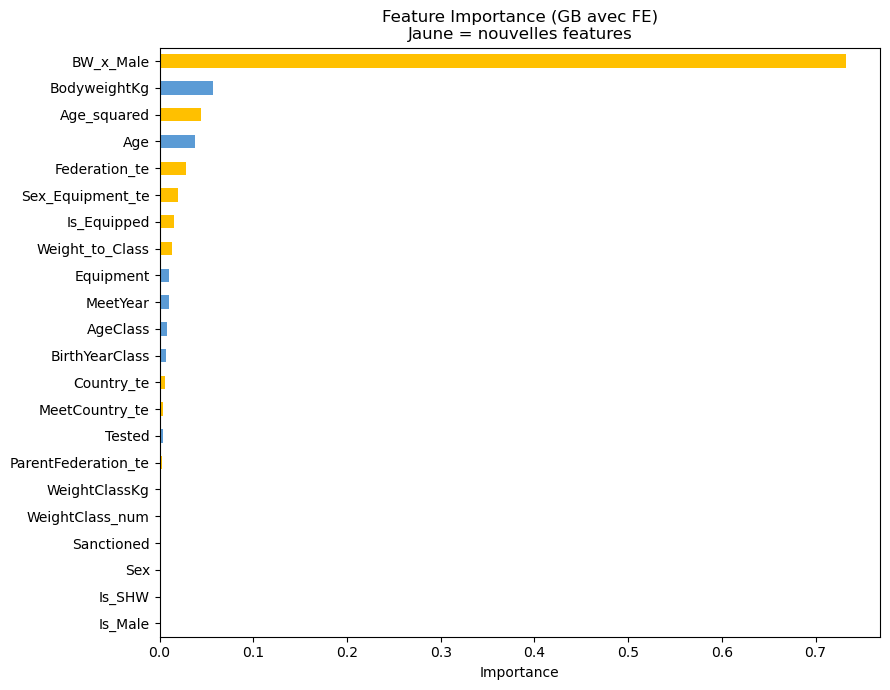


Top 10 features:
BW_x_Male           0.7322
BodyweightKg        0.0567
Age_squared         0.0442
Age                 0.0380
Federation_te       0.0284
Sex_Equipment_te    0.0191
Is_Equipped         0.0149
Weight_to_Class     0.0135
Equipment           0.0102
MeetYear            0.0101
dtype: float64


In [6]:
gb.fit(X, y)

importances = pd.Series(gb.feature_importances_, index=ALL_FEATURES)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#FFC000' if f in new_features + te_cols else '#5B9BD5' for f in importances.index]
importances.plot(kind='barh', ax=ax, color=colors)
ax.set_title('Feature Importance (GB avec FE)\nJaune = nouvelles features')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print('\nTop 10 features:')
print(importances.sort_values(ascending=False).head(10).round(4))

## 6. Analyse des résidus

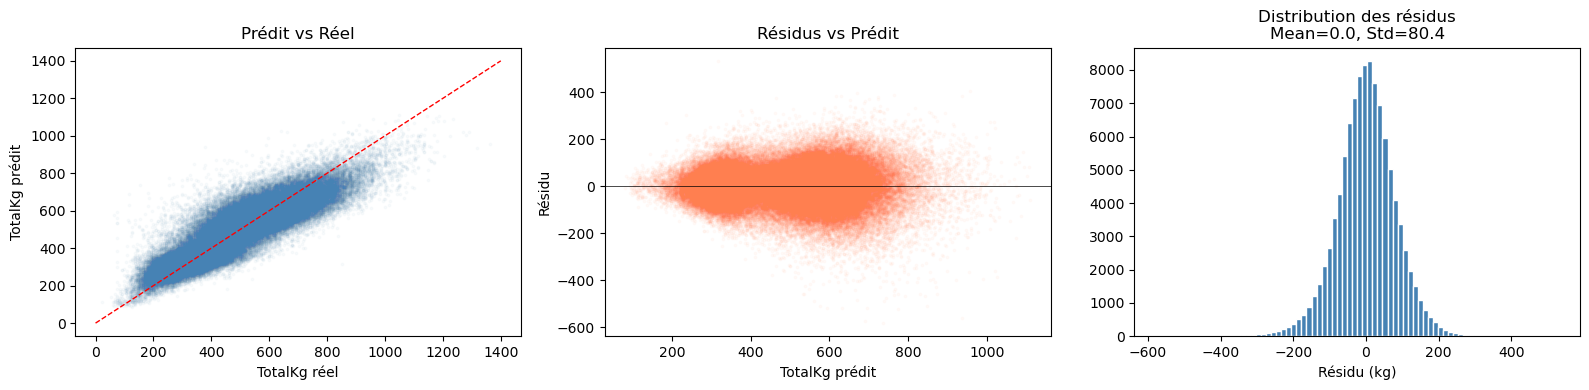

In [7]:
from sklearn.model_selection import cross_val_predict

y_pred_cv = cross_val_predict(gb, X, y, cv=kf)
residuals = y - y_pred_cv

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Pred vs Actual
axes[0].scatter(y, y_pred_cv, alpha=0.03, s=3, color='steelblue')
axes[0].plot([0, 1400], [0, 1400], 'r--', linewidth=1)
axes[0].set_xlabel('TotalKg réel')
axes[0].set_ylabel('TotalKg prédit')
axes[0].set_title('Prédit vs Réel')

# Résidus vs Prédit
axes[1].scatter(y_pred_cv, residuals, alpha=0.03, s=3, color='coral')
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].set_xlabel('TotalKg prédit')
axes[1].set_ylabel('Résidu')
axes[1].set_title('Résidus vs Prédit')

# Distribution résidus
axes[2].hist(residuals, bins=80, color='steelblue', edgecolor='white')
axes[2].set_xlabel('Résidu (kg)')
axes[2].set_title(f'Distribution des résidus\nMean={residuals.mean():.1f}, Std={residuals.std():.1f}')

plt.tight_layout()
plt.show()

## 7. Soumission

In [ ]:
preds = gb.predict(X_test)
preds = np.clip(preds, 0, None)

submission = pd.DataFrame({'id': test['id'], 'TotalKg': preds})
submission.to_csv('submission_fe.csv', index=False)

print('Submission sauvegardée : submission_fe.csv')
print(submission['TotalKg'].describe().round(2))

Submission sauvegardée : submission_fe.csv
count    45000.00
mean       494.73
std        151.18
min         56.00
25%        355.34
50%        513.10
75%        607.70
max       1173.99
Name: TotalKg, dtype: float64


Exception ignored in: <function ResourceTracker.__del__ at 0x106265bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10517dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x118065bc0>
Traceback (most recent call last

## 8. Résumé des features créées

| Feature | Type | Logique |
|---------|------|--------|
| `WeightClass_num` | Numérique | Extraction de la partie numérique de WeightClassKg |
| `Sex_Equipment` | Catégorielle | Interaction Sex × Equipment |
| `Weight_to_Class` | Numérique | BodyweightKg / WeightClass (proximité à la limite) |
| `Age_squared` | Numérique | Age² (relation non-linéaire avec la performance) |
| `Is_SHW` | Binaire | Catégorie poids lourds (classe avec +) |
| `Is_Male` | Binaire | Sexe masculin |
| `Is_Equipped` | Binaire | Utilise de l'équipement (pas Raw) |
| `BW_x_Male` | Numérique | BodyweightKg × Is_Male (interaction clé) |
| `*_te` | Numérique | Target encoding (Federation, Country, etc.) |

**Prochaines étapes :** LightGBM/XGBoost, hyperparameter tuning, cross-validated target encoding (pour éviter le leakage).